# k-Nearest Neighbors

In this lab you will explore tuning a k-Nearest Neighbors model for image classification.

We will use the [Fashion MNIST dataset](https://github.com/zalandoresearch/fashion-mnist) provided by the [Keras library](https://keras.io/api/datasets/fashion_mnist/).

In [22]:
import glob
import imageio
import skimage
from matplotlib import pyplot as plt
import numpy as np

from sklearn.neighbors import KNeighborsClassifier
from keras.datasets import fashion_mnist

Here we load the dataset and show some example images.  Each class is a different category of clothing like shoe, t-shirt, or dress.  The classes are mostly distinguishable by shape, and so they are a good candidate for classification using the [HOG (Histogram of Gradients)](https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html) descriptor which captures shape well.

In [23]:
(train_images,train_labels),(val_images,val_labels) = fashion_mnist.load_data()

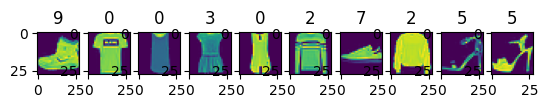

In [24]:
fig,axes = plt.subplots(1,10)
for i,ax in enumerate(axes):
    axes[i].imshow(train_images[i])
    axes[i].set_title(train_labels[i])

Now what we have are lists `train_images` and `train_labels` containing the images and labels for the training set, and the same for the validation set.

1. Compute a HOG descriptor for each image to make two lists, `train_descriptors` and `val_descriptors` (```skimage.feature.hog```).

In [25]:
from skimage.feature import hog
train_descriptors, val_descriptors = [], []

for image in train_images:
  td = hog(image)
  train_descriptors.append(td)

for image in val_images:
  vd = hog(image)
  val_descriptors.append(vd)

2. Build a k-nearest neighbors classifier on the training set (```sklearn.neighbors.KNeighborsClassifier```).

This model will find the $k$ nearest neighbors to the query point and output the most common label.  Use the default value of $k$.

Run the model on the test set and print out the accuracy (```sklearn.metrics.accuracy_score``` or simply use ```model.score```).

In [26]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Fit the model
knn = KNeighborsClassifier()
knn.fit(train_descriptors, train_labels)

# Check the performance of the model with the validation dataset
val_predicts = knn.predict(val_descriptors)
accuracy_score(val_predicts, val_labels)

0.8295


3. Test $k$ from 1 to 101 in increments of 10 and make a plot of the train and test accuracy versus $k$.  Analyze the trade-off between over- and underfitting changes as $k$ increases.  Which is the best setting of $k$?

In [27]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

scores = []
for k in range(1, 102, 10):
  # Fit the model
  knn = KNeighborsClassifier(n_neighbors=k)
  knn.fit(train_descriptors, train_labels)

  # Check the performance of the model with the validation dataset
  val_predicts = knn.predict(val_descriptors)
  score = accuracy_score(val_predicts, val_labels)

  scores.append((k, score))

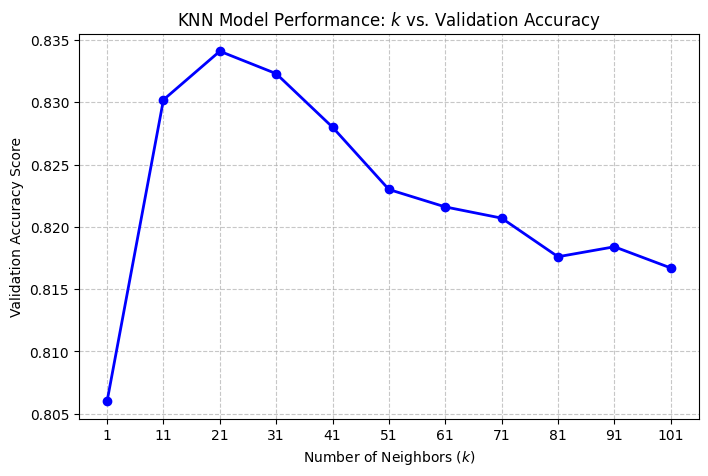

In [28]:
# Plot k versus the score
# Unpack k and scores for plotting
k_s, score_vals = zip(*scores)

# Make the plot
plt.figure(figsize=(8, 5))
plt.plot(
    k_s, score_vals, marker='o', linestyle='-', color='b', linewidth=2
)
plt.title('KNN Model Performance: $k$ vs. Validation Accuracy')
plt.xlabel('Number of Neighbors ($k$)')
plt.ylabel('Validation Accuracy Score')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(k_s)
plt.show()

In [29]:
# What is the best fitting of k?
m = max(scores, key=lambda x: x[1])
print(f"K value with the highest score: {m[0]}")

K value with the highest score: 21
